In [1]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, AIMessage, SystemMessage, RemoveMessage
from typing import TypedDict, Annotated
from langchain_groq import ChatGroq
from langchain_core.messages.utils import count_tokens_approximately,trim_messages

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
SYSTEM_PROMPT = """
You are a concise chatbot.

Rules:
- Answer in 1-2 short sentences only.
- Maximum 30 words per response.
- Do not provide explanations, roadmaps, lists, or detailed steps unless explicitly asked.
- For simple questions, give a simple answer.
- Never repeat previous conversation unnecessarily.
- Prioritize answering the user's latest message.
"""

llm = ChatGroq(model='openai/gpt-oss-20b',temperature=0.1,max_tokens=1000)
memory = InMemorySaver()

In [3]:
class ChatState(MessagesState):
    summary: Annotated[str, "Summary of the conversation so far"] = ""

In [11]:
def chat_node(state: ChatState):
    messages = state["messages"]

    system_prompt = SYSTEM_PROMPT
    if state.get("summary"):
        system_prompt += f"\nConversation summary:\n{state['summary']}"

    messages = [SystemMessage(content=system_prompt)] + messages
        
    response = llm.invoke(messages)
    return {"messages": [response]}

def summarize_node(state: ChatState):
    messages = state["messages"]

    print(f"Tokens: {count_tokens_approximately(state['messages'])}")
    if count_tokens_approximately(state['messages']) <= 200:
        return {}

    trimmed_messages = trim_messages(
        messages=messages,
        max_tokens=200,
        token_counter=count_tokens_approximately,
        strategy="last",
        include_system=True,
        start_on="human"
    )

    kept_ids = {message.id for message in trimmed_messages}
    dropped_messages = [m for m in messages if m.id not in kept_ids]

    if not dropped_messages:
        return {}

    existing_summary = state.get("summary", "")

    summary_prompt = f"""
    Update the conversation summary.

    Existing summary:
    {existing_summary}

    New messages:
    {dropped_messages}

    Keep the summary very short, maximum 50 words.
    """

    summary = llm.invoke([
        SystemMessage(content=summary_prompt)
    ]).content

    return {
        "messages": [RemoveMessage(id=m.id) for m in dropped_messages],
        "summary": summary
    }

In [12]:
graph = StateGraph(ChatState)

graph.add_node("summarize_node", summarize_node)
graph.add_node("chat_node", chat_node)

graph.add_edge(START, "summarize_node")
graph.add_edge("summarize_node", "chat_node")
graph.add_edge("chat_node", END)

workflow = graph.compile(checkpointer=memory)

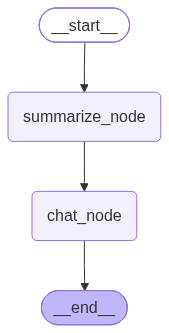

In [6]:
from IPython.display import display, Image

display(Image(workflow.get_graph().draw_mermaid_png()))

In [13]:
CONFIG = { 'configurable' :{ 'thread_id': '10'} }

In [14]:
workflow.invoke({"messages": [HumanMessage(content="Hi, I'm Vikas.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I'm a developer.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I use React and Node.js.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I'm learning system design.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I'm learning LangGraph too.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I'm building a chatbot.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="It uses LangGraph.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I want to add memory.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="I will add tools later.")]}, config=CONFIG)
workflow.invoke({"messages": [HumanMessage(content="What's my name?")]}, config=CONFIG)

Tokens: 8
Tokens: 30
Tokens: 60
Tokens: 95
Tokens: 132
Tokens: 169
Tokens: 210
Tokens: 228
Tokens: 256
Tokens: 239


{'messages': [HumanMessage(content='It uses LangGraph.', additional_kwargs={}, response_metadata={}, id='350150d8-5002-47cd-bff8-fdb62505ee0b'),
  AIMessage(content='Do you need help setting up the graph, defining nodes, or integrating it with your React frontend?', additional_kwargs={'reasoning_content': 'User: "It uses LangGraph." They want help building a chatbot using LangGraph. They didn\'t ask a specific question. We need to respond concisely, 1-2 short sentences, max 30 words. We should ask clarifying question or give a brief suggestion. Maybe: "Do you need help setting up the graph, defining nodes, or integrating with your React frontend?" That is 2 sentences, under 30 words. Let\'s count: "Do you need help setting up the graph, defining nodes, or integrating with your React frontend?" That\'s 20 words. Good.'}, response_metadata={'token_usage': {'completion_tokens': 150, 'prompt_tokens': 334, 'total_tokens': 484, 'completion_time': 0.162170695, 'completion_tokens_details': {'r

In [15]:
current_state = workflow.get_state(CONFIG).values

print(current_state['summary'])
for message in current_state["messages"]:
    print(f"{message.type}: {message.content}")


User Vikas, a React/Node developer, is learning system design and LangGraph, and is building a chatbot. Assistant is asking which part they need help with.
human: It uses LangGraph.
ai: Do you need help setting up the graph, defining nodes, or integrating it with your React frontend?
human: I want to add memory.
ai: Use LangGraph’s built‑in memory store (e.g., `MemoryStore` or `ConversationBufferMemory`) and attach it to your graph’s state. Then the bot can recall past turns.
human: I will add tools later.
ai: Add a `MemoryStore` (e.g., `ConversationBufferMemory`) to your graph’s state and pass it to the `Graph` constructor. The bot will then retain context across turns.
human: What's my name?
ai: Your name is Vikas.


In [16]:
workflow.invoke({"messages": [HumanMessage(content="What i am currently learning")]}, config=CONFIG)

Tokens: 180


{'messages': [HumanMessage(content='It uses LangGraph.', additional_kwargs={}, response_metadata={}, id='350150d8-5002-47cd-bff8-fdb62505ee0b'),
  AIMessage(content='Do you need help setting up the graph, defining nodes, or integrating it with your React frontend?', additional_kwargs={'reasoning_content': 'User: "It uses LangGraph." They want help building a chatbot using LangGraph. They didn\'t ask a specific question. We need to respond concisely, 1-2 short sentences, max 30 words. We should ask clarifying question or give a brief suggestion. Maybe: "Do you need help setting up the graph, defining nodes, or integrating with your React frontend?" That is 2 sentences, under 30 words. Let\'s count: "Do you need help setting up the graph, defining nodes, or integrating with your React frontend?" That\'s 20 words. Good.'}, response_metadata={'token_usage': {'completion_tokens': 150, 'prompt_tokens': 334, 'total_tokens': 484, 'completion_time': 0.162170695, 'completion_tokens_details': {'r